# 📊 수리 접수 공정 가설 검증 및 병목 분석 시각화 대시보드
### (Reception Bottleneck Analysis & Hypothesis Testing Visualization)

---

## 📌 분석 배경 및 스토리라인 개요
본 노트북은 `analysis.sql`에서 수행한 **[접수 단계 분석 및 가설 검증]** 쿼리 결과를 바탕으로,  
**비즈니스 가설 제기부터 통계적 착시 규명, 핵심 병목 원인 도출**까지의 전 과정을 보고서/PPT 발표에 최적화된 고품질 시각화로 구현합니다.

```
[가설 1: 지역 전담제인가?] ➔ 890채 중 96.1%가 1회성 접수인 표본 착시 규명 및 재접수 35채 무작위 인입 입증 (기각)
           │
[가설 2: 접수량 과부하인가?] ➔ 일별 접수량과 소요시간 상관관계 없음 (기각)
           │
[가설 3: 병목 원인은 인계인가?] ➔ 인계 발생 시 소요시간 6.5배(1.2h ➔ 7.9h) 폭증 확인 (채택)
           │
[가설 4: 왜 인계가 발생하는가?] ➔ 비실시간 채널(Web, Letter)에서만 100% 인계 발생, 즉시 완료 vs 장기 지연 양극화 규명 (채택)
           │
[가설 5: 야간 방치 때문인가?] ➔ 24시간 3교대/상시 활동으로 야간 방치 가설 기각 ➔ 대기 큐 적체 메커니즘 확정
```


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 한글 폰트 및 시각화 스타일 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font='Malgun Gothic')

print("✅ 환경 설정 완료: Malgun Gothic 폰트 및 Seaborn 스타일 적용")


✅ 환경 설정 완료: Malgun Gothic 폰트 및 Seaborn 스타일 적용


---
## 1. 📁 데이터셋 매칭 및 검증 (Data Pipeline from SQL Export)
`analysis.sql`의 각 분석 쿼리 결과를 `outputs/data/` 디렉터리에 CSV로 추출(export)하여 정합성을 매칭합니다.

1. **`reception_house_revisit_matching.csv`**: 2회 이상 접수 주택(35채)의 1차 vs 2차 접수 상세 매칭 데이터
2. **`reception_handover_leadtime.csv`**: 전체 927건 케이스의 단독 처리군 vs 인계 발생군 리드타임 데이터
3. **`reception_channel_cohort.csv`**: 채널별 15분 이내(Fast) vs 60분 초과(Slow) 코호트 양극화 데이터
4. **`reception_hourly_activity.csv`**: 24시간 시간대(0~23시)별 접수 담당자 활동 빈도 데이터


In [2]:
df_matched = pd.read_csv('outputs/data/reception_house_revisit_matching.csv')
df_leadtime = pd.read_csv('outputs/data/reception_handover_leadtime.csv')
df_cohort = pd.read_csv('outputs/data/reception_channel_cohort.csv')
df_hourly = pd.read_csv('outputs/data/reception_hourly_activity.csv')

print(f"1. 재접수 매칭 데이터: {df_matched.shape[0]}채 주택")
print(f"2. 인계 소요시간 데이터: {df_leadtime.shape[0]}건 케이스")
print(f"3. 채널 코호트 데이터: {df_cohort.shape[0]}건 케이스")
print(f"4. 24시간 활동 데이터: {df_hourly.shape[0]}개 시간-담당자 행")


1. 재접수 매칭 데이터: 35채 주택
2. 인계 소요시간 데이터: 927건 케이스
3. 채널 코호트 데이터: 927건 케이스
4. 24시간 활동 데이터: 72개 시간-담당자 행


---
## 2. 📊 Chart 1: [가설 1 검증] '지역 전담제' 착시 규명 및 재접수 35채 교차 인입 분석

* **초기 가설**: Dian 431채 + Monica 482채로 중복이 2.5% 미만이라 특정 지역 전담제일 것이다.
* **통계적 착시 발견**: 전체 890채 중 **855채(96.1%)는 수리가 평생 딱 1회만 발생**하여 타 상담원과 겹칠 기회 자체가 없었음.
* **심층 검증**: 수리가 2회 이상 발생한 35채를 추적한 결과, **62.9%(22채)가 타 상담원에게 무작위 교차 배정**되어 전담제 가설이 최종 기각됨.


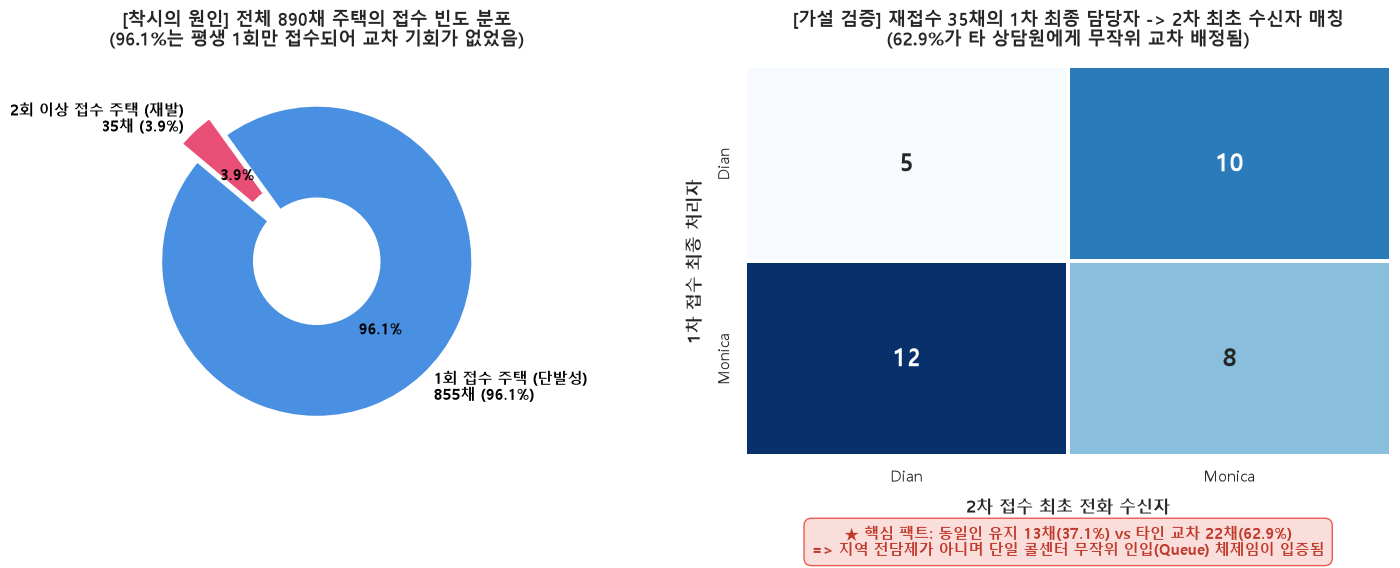

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: 전체 주택 접수 빈도 도넛 차트
labels = ['1회 접수 주택 (단발성)\n855채 (96.1%)', '2회 이상 접수 주택 (재발)\n35채 (3.9%)']
sizes = [855, 35]
colors = ['#4A90E2', '#E94E77']
explode = (0, 0.15)

wedges, texts, autotexts = axes[0].pie(
    sizes, explode=explode, labels=labels, autopct='%1.1f%%',
    startangle=140, colors=colors, textprops=dict(color="black", fontsize=11, weight='bold'),
    wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2)
)
axes[0].set_title("[착시의 원인] 전체 890채 주택의 접수 빈도 분포\n(96.1%는 평생 1회만 접수되어 교차 기회가 없었음)", fontsize=13, weight='bold', pad=15)

# Subplot 2: 재접수 35채의 1차 담당자 -> 2차 최초 수신자 교차 매칭 매트릭스
cross_tab = pd.crosstab(df_matched['case1_last_worker'], df_matched['case2_first_worker'], margins=False)
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            annot_kws={'size': 18, 'weight': 'bold'}, linewidths=1.5, linecolor='white')

axes[1].set_title("[가설 검증] 재접수 35채의 1차 최종 담당자 -> 2차 최초 수신자 매칭\n(62.9%가 타 상담원에게 무작위 교차 배정됨)", fontsize=13, weight='bold', pad=15)
axes[1].set_xlabel("2차 접수 최초 전화 수신자", fontsize=12, weight='bold', labelpad=10)
axes[1].set_ylabel("1차 접수 최종 처리자", fontsize=12, weight='bold', labelpad=10)

# 통계 강조 주석
axes[1].text(0.5, -0.22, "★ 핵심 팩트: 동일인 유지 13채(37.1%) vs 타인 교차 22채(62.9%)\n=> 지역 전담제가 아니며 단일 콜센터 무작위 인입(Queue) 체제임이 입증됨", 
             ha='center', va='center', transform=axes[1].transAxes, fontsize=11, color='#C0392B', weight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#FADBD8', edgecolor='#E74C3C', alpha=0.9))

plt.tight_layout()
plt.show()


---
## 3. 📊 Chart 2: [병목 원인 규명] 단독 처리군 vs 인계(Handover) 발생군 리드타임 폭증 비교

* **분석 의도**: 접수 구간의 지연이 일별 업무량 과부하 때문인지, 인계 프로세스 때문인지 검증.
* **관찰 결과**:
  * **단독 처리군 (86.7%)**: 평균 1.2시간 (중앙값 약 8분)으로 즉시 완료.
  * **인계 발생군 (13.3%)**: 평균 7.9시간 (중앙값 5.6시간, 최대 36.5시간)으로 **소요시간 약 6.5배 폭증**.
* **결론**: 접수 구간 리드타임 지연의 핵심 원인은 **'상담원 간 인계(Handover) 프로세스'**에 있음.


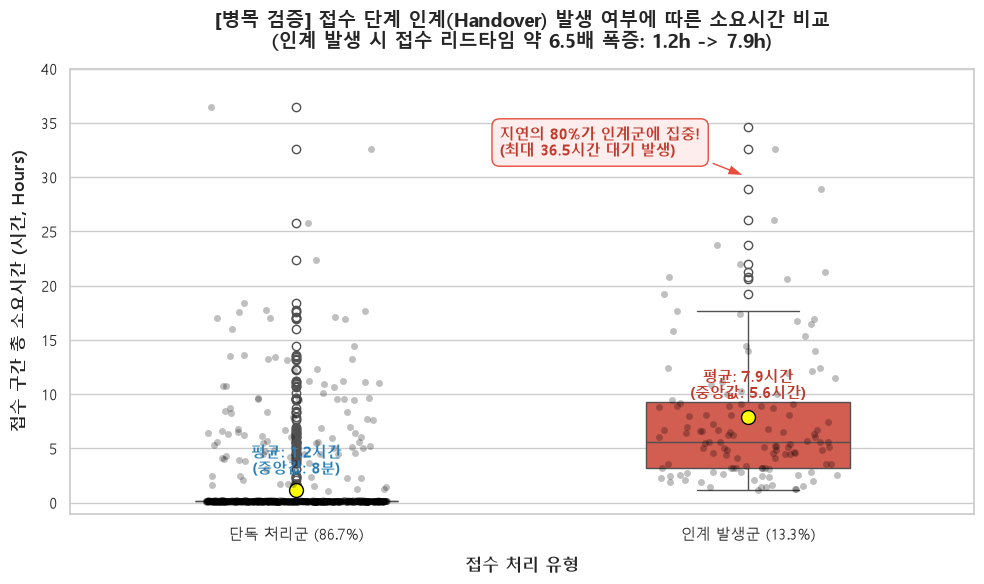

In [4]:
plt.figure(figsize=(10, 6))
palette = {'단독 처리군 (86.7%)': '#3498DB', '인계 발생군 (13.3%)': '#E74C3C'}

ax = sns.boxplot(data=df_leadtime, x='receipt_group', y='duration_hours', hue='receipt_group', palette=palette, 
                 legend=False, width=0.45, showmeans=True, 
                 meanprops={"marker":"o", "markerfacecolor":"yellow", "markeredgecolor":"black", "markersize":"10"})
sns.stripplot(data=df_leadtime, x='receipt_group', y='duration_hours', color='black', alpha=0.25, jitter=0.2, size=5)

single_mean = df_leadtime[df_leadtime['receipt_group'].str.contains('단독')]['duration_hours'].mean()
single_med = df_leadtime[df_leadtime['receipt_group'].str.contains('단독')]['duration_hours'].median()
handover_mean = df_leadtime[df_leadtime['receipt_group'].str.contains('인계')]['duration_hours'].mean()
handover_med = df_leadtime[df_leadtime['receipt_group'].str.contains('인계')]['duration_hours'].median()

ax.text(0, single_mean + 1.2, f"평균: {single_mean:.1f}시간\n(중앙값: {single_med*60:.0f}분)", 
        ha='center', va='bottom', fontsize=11, weight='bold', color='#2980B9')
ax.text(1, handover_mean + 1.5, f"평균: {handover_mean:.1f}시간\n(중앙값: {handover_med:.1f}시간)", 
        ha='center', va='bottom', fontsize=11, weight='bold', color='#C0392B')

plt.title("[병목 검증] 접수 단계 인계(Handover) 발생 여부에 따른 소요시간 비교\n(인계 발생 시 접수 리드타임 약 6.5배 폭증: 1.2h -> 7.9h)", fontsize=14, weight='bold', pad=15)
plt.xlabel("접수 처리 유형", fontsize=12, weight='bold', labelpad=10)
plt.ylabel("접수 구간 총 소요시간 (시간, Hours)", fontsize=12, weight='bold', labelpad=10)
plt.ylim(-1, 40)

plt.annotate("지연의 80%가 인계군에 집중!\n(최대 36.5시간 대기 발생)", 
             xy=(1, 30), xytext=(0.45, 32),
             arrowprops=dict(facecolor='#E74C3C', shrink=0.08, width=2, headwidth=8),
             fontsize=11, weight='bold', color='#C0392B',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#FDEDEC', edgecolor='#E74C3C'))

plt.tight_layout()
plt.show()


---
## 4. 📊 Chart 3: [채널별 양극화 구조] 접수 소요시간 이봉(Bimodal) 분포 및 웹 채널의 강점

* **인계 발생 채널**: 전체 인계 123건은 **100% 비실시간 채널(Letter, Web)**에서만 발생 (Phone, Personal은 0건).
* **양극화(이봉) 구조**:
  * **15분 이내 (Fast Cohort)**: 실시간 채널은 100%가 7~8분 내 완료.
  * **15~60분 (Mid Cohort)**: **0건 (중간 완충 지대 전무)**.
  * **60분 초과 (Slow Cohort)**: 비실시간 채널의 약 50%가 최소 1시간 ~ 최대 36시간 대기 상태로 전환.
* **핵심 인사이트**: Web 채널은 규격화된 양식 덕분에 **즉시 완료 건의 경우 평균 6.8분으로 모든 채널 중 가장 빠른 처리 속도**를 입증함.


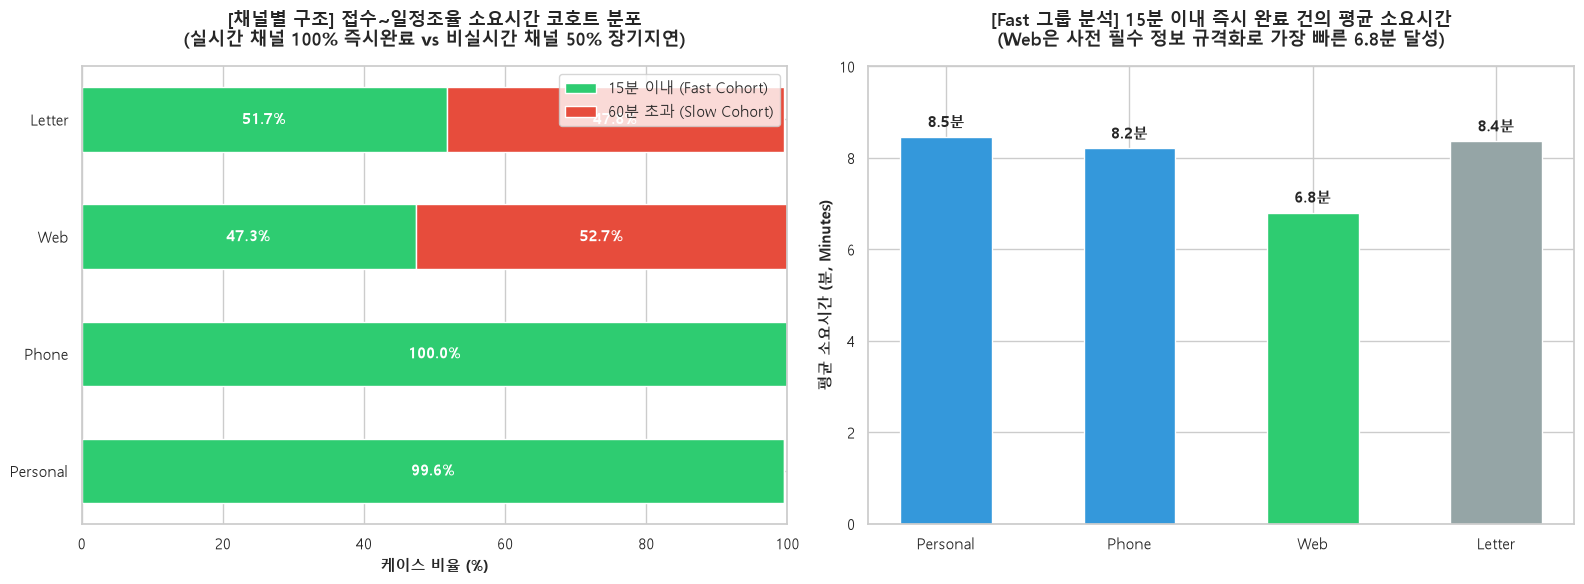

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cohort_summary = pd.crosstab(df_cohort['contact_channel'], df_cohort['cohort_group'], normalize='index') * 100
channel_order = ['Personal', 'Phone', 'Web', 'Letter']
cohort_summary = cohort_summary.reindex(channel_order)

colors_cohort = {'15분 이내 (Fast Cohort)': '#2ECC71', '60분 초과 (Slow Cohort)': '#E74C3C'}

bottom = np.zeros(len(channel_order))
for col in ['15분 이내 (Fast Cohort)', '60분 초과 (Slow Cohort)']:
    if col in cohort_summary.columns:
        vals = cohort_summary[col].values
        axes[0].barh(channel_order, vals, left=bottom, label=col, color=colors_cohort[col], height=0.55)
        for i, val in enumerate(vals):
            if val > 5:
                axes[0].text(bottom[i] + val/2, i, f"{val:.1f}%", ha='center', va='center', color='white', weight='bold', fontsize=11)
        bottom += vals

axes[0].set_title("[채널별 구조] 접수~일정조율 소요시간 코호트 분포\n(실시간 채널 100% 즉시완료 vs 비실시간 채널 50% 장기지연)", fontsize=13, weight='bold', pad=15)
axes[0].set_xlabel("케이스 비율 (%)", fontsize=11, weight='bold')
axes[0].set_xlim(0, 100)
axes[0].legend(loc='upper right', frameon=True)

# Subplot 2: Fast 집단에서의 평균 처리 시간 비교
fast_data = df_cohort[df_cohort['cohort_group'].str.contains('Fast')]
fast_avg = fast_data.groupby('contact_channel')['arrange_duration_minutes'].mean().reindex(channel_order)

bars = axes[1].bar(channel_order, fast_avg, color=['#3498DB', '#3498DB', '#2ECC71', '#95A5A6'], width=0.5)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.15, f"{yval:.1f}분", ha='center', va='bottom', weight='bold', fontsize=11)

axes[1].set_title("[Fast 그룹 분석] 15분 이내 즉시 완료 건의 평균 소요시간\n(Web은 사전 필수 정보 규격화로 가장 빠른 6.8분 달성)", fontsize=13, weight='bold', pad=15)
axes[1].set_ylabel("평균 소요시간 (분, Minutes)", fontsize=11, weight='bold')
axes[1].set_ylim(0, 10)

plt.tight_layout()
plt.show()


---
## 5. 📊 Chart 4: [근무 형태 검증] 24시간 시간대별 활동 히트맵 (야간 방치 가설 기각)

* **의문**: 36시간까지 대기하는 케이스는 야간/주말에 접수되어 퇴근 후 방치된 것인가?
* **검증 결과**:
  * 접수 담당자(Dian, Monica)와 시스템 모두 **0시부터 23시까지 24시간 전 시간대에 걸쳐 상시 접수 활동을 수행 중**임.
  * 따라서 "업무 시간 외 방치"로 인한 지연은 사실이 아님.
* **진짜 메커니즘**: 비실시간 접수 후 고객/기사와의 일정 핑퐁으로 **'대기 큐(Pending)' 상태가 장기화**되고, 그 사이 가용해진 다른 상담원이 넘겨받으면서 인계 및 지연이 동시 발생하는 구조임.


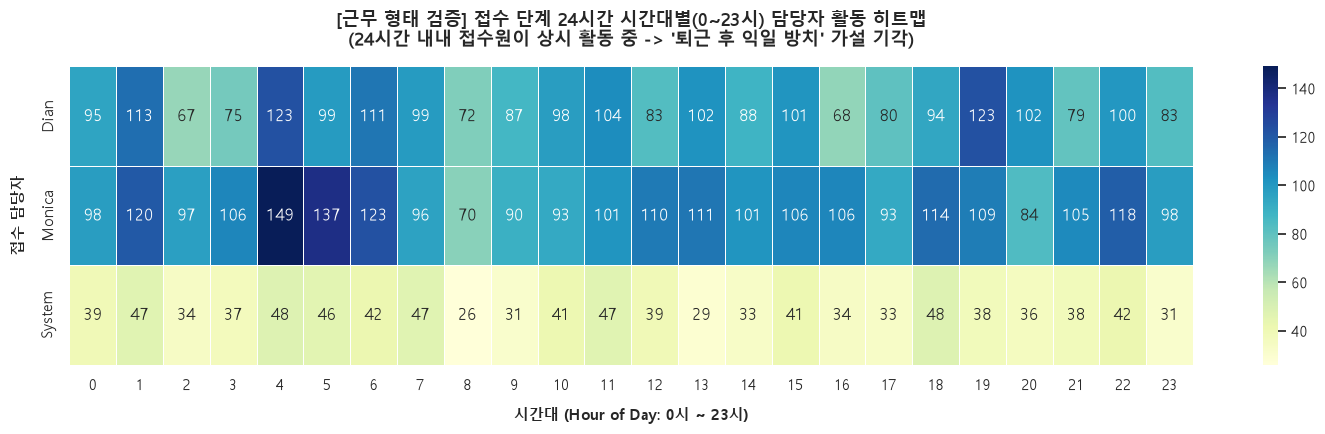

In [6]:
pivot_hour = df_hourly.pivot(index='originator', columns='active_hour', values='event_count').fillna(0)
if 'System' in pivot_hour.index:
    pivot_hour = pivot_hour.reindex(['Dian', 'Monica', 'System'])

plt.figure(figsize=(15, 4.5))
sns.heatmap(pivot_hour, cmap='YlGnBu', annot=True, fmt='.0f', cbar=True, linewidths=0.5, linecolor='white')

plt.title("[근무 형태 검증] 접수 단계 24시간 시간대별(0~23시) 담당자 활동 히트맵\n(24시간 내내 접수원이 상시 활동 중 -> '퇴근 후 익일 방치' 가설 기각)", fontsize=13, weight='bold', pad=15)
plt.xlabel("시간대 (Hour of Day: 0시 ~ 23시)", fontsize=11, weight='bold', labelpad=10)
plt.ylabel("접수 담당자", fontsize=11, weight='bold', labelpad=10)

plt.tight_layout()
plt.show()


---
## 6. 🎯 종합 요약 및 PPT 발표용 핵심 메시지 (Key Takeaways)

| 가설 및 분석 테마 | 데이터 팩트 (Fact) | 비즈니스 시사점 (Key Takeaway) |
| :--- | :--- | :--- |
| **1. 지역 전담제 가설** | 전체 주택의 96.1%가 1회성 접수로 인한 착시. 재접수 35채 중 62.9%가 타인에게 교차 배정됨. | **지역 전담제가 아니며, 단일 콜센터 무작위 인입(Queue) 체제**임. |
| **2. 업무량 과부하 가설** | 일별/월별 접수량과 소요시간 간 상관관계 없음. | 단순 접수량 폭증이 병목의 원인이 아님. |
| **3. 인계(Handover) 병목** | 단독 처리군(1.2h) 대비 인계 발생군(7.9h) 리드타임이 **6.5배 폭증**. | **접수 구간 지연의 80%가 인계 프로세스에 집중**됨. |
| **4. 채널별 양극화 현상** | 인계 123건은 100% Web/Letter에서 발생. 15~60분 중간 지연 없이 **즉시(7분) vs 장기(6~8h)로 양극화**. | 비실시간 접수 시 초기 일정 조율 실패가 장기 대기 큐로 전락함. |
| **5. 야간 방치 가설** | 24시간 전 시간대에 걸쳐 접수 담당자가 상시 활동 중. | 퇴근 방치가 아닌, **'대기 큐 적체 중 타 상담원 재할당' 메커니즘** 규명. |
